# Retail Sales – Data Visualization 


## Step 1 – Setup (libraries, folders, colour palette, helpers)

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib


IN_NOTEBOOK = "__file__" not in globals()
if not IN_NOTEBOOK:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

warnings.filterwarnings("ignore")


ROOT = Path(__file__).resolve().parent.parent if not IN_NOTEBOOK else Path.cwd().parent
DATA_RAW = ROOT / "data" / "retail_customer_sales_dataset.csv"
DATA_CLEAN = ROOT / "data" / "cleaned_retail_data.csv"
OUT = ROOT / "outputs"
CHART_DIR = OUT / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

BLUE = "#1F4E79"      
LIGHT_BLUE = "#7FA7CF"
GRAY = "#B8BFC9"      
ORANGE = "#E07B39"    
SEG_COLORS = {"Consumer": "#1F4E79", "Corporate": "#5B9BD5", "Home Office": "#A9BCD0"}
SAT_COLORS = {"Low": ORANGE, "Medium": GRAY, "High": BLUE}

plt.rcParams.update({
    "figure.figsize": (9, 5.2),
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.edgecolor": "#555555",
})


def inr_m(x, pos=None):   
    return f"₹{x / 1e6:g}M"


def inr_k(x, pos=None):   
    return f"₹{x / 1e3:g}K"


def m1(x):                
    return f"₹{x / 1e6:.1f}M"


def light_ygrid(ax):
    """Only faint horizontal gridlines (no chart junk)."""
    ax.yaxis.grid(True, color="#E3E6EA", linewidth=0.8)
    ax.set_axisbelow(True)


CHARTS = []  

def finish(fig, key, title, section, caption):
    """Save the chart as PNG, remember its caption, show it when in a notebook."""
    path = CHART_DIR / f"{key}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    CHARTS.append({"file": path.name, "title": title, "section": section, "caption": caption})
    if IN_NOTEBOOK:
        from IPython.display import Markdown, display
        plt.show()
        display(Markdown(f"**Insight:** {caption}"))
    plt.close(fig)


def strength(r):
    a = abs(r)
    return "very weak" if a < 0.1 else "weak" if a < 0.3 else "moderate" if a < 0.6 else "strong"

## Step 2 – Load and clean the data

In [2]:
raw = pd.read_csv(DATA_RAW)
df = raw.copy()
log = {"rows_raw": int(len(raw))}
print("Raw shape:", raw.shape)
print(raw.isna().sum()[raw.isna().sum() > 0])

Raw shape: (7084, 24)
Delivery_Date         106
Age                   142
Income                253
Discount               71
Customer_Rating       428
Satisfaction_Level    179
dtype: int64


In [3]:

for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("string").str.strip()

df["Region"] = df["Region"].str.lower().map(
    {"north": "North", "nort": "North", "south": "South", "sth": "South", "east": "East", "west": "West"})
df["Gender"] = df["Gender"].str.lower().map(
    {"male": "Male", "m": "Male", "female": "Female", "f": "Female"})

In [4]:

DATE_FORMATS = [
    (r"^\d{4}-\d{2}-\d{2}$", "%Y-%m-%d"),
    (r"^\d{2}-[A-Za-z]{3}-\d{4}$", "%d-%b-%Y"),
    (r"^\d{2}/\d{2}/\d{4}$", "%d/%m/%Y"),
    (r"^\d{2}-\d{2}-\d{4}$", "%m-%d-%Y"),
]


def parse_mixed_dates(s):
    s = s.astype("string")
    result = None
    for pattern, fmt in DATE_FORMATS:
        match = s.str.match(pattern).fillna(False).astype(bool)
        part = pd.to_datetime(s.where(match), format=fmt, errors="coerce")
        result = part if result is None else result.fillna(part)
    return result


df["Order_Date"] = parse_mixed_dates(df["Order_Date"])
df["Delivery_Date"] = parse_mixed_dates(df["Delivery_Date"])
log["unparsed_order_dates"] = int(df["Order_Date"].isna().sum())

In [5]:

n0 = len(df)
df = df.drop_duplicates()
log["exact_duplicate_rows_removed"] = int(n0 - len(df))
n1 = len(df)
df = df.drop_duplicates(subset="Transaction_ID", keep="first")
log["repeated_transaction_ids_removed"] = int(n1 - len(df))

In [6]:

bad_age = (df["Age"] < 18) | (df["Age"] > 100)
log["invalid_age_set_to_nan"] = int(bad_age.sum())
df.loc[bad_age, "Age"] = np.nan

bad_disc = (df["Discount"] < 0) | (df["Discount"] > 0.5)
log["invalid_discount_set_to_nan"] = int(bad_disc.sum())
df.loc[bad_disc, "Discount"] = np.nan

q1, q3 = df["Income"].quantile([0.25, 0.75])
income_fence = q3 + 3 * (q3 - q1)         
bad_inc = df["Income"] > income_fence
log["extreme_income_set_to_nan"] = int(bad_inc.sum())
df.loc[bad_inc, "Income"] = np.nan

bad_delivery = df["Delivery_Date"] < df["Order_Date"]
log["delivery_before_order_set_to_nan"] = int(bad_delivery.sum())
df.loc[bad_delivery, "Delivery_Date"] = pd.NaT


df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.to_period("M").dt.to_timestamp()
df["Profit_Margin"] = df["Profit"] / df["Sales"]
df["Returned_Flag"] = (df["Returned"] == "Yes").astype(int)

log["rows_clean"] = int(len(df))
df.to_csv(DATA_CLEAN, index=False)
(OUT / "cleaning_log.json").write_text(json.dumps(log, indent=2))
print(json.dumps(log, indent=2))

{
  "rows_raw": 7084,
  "unparsed_order_dates": 0,
  "exact_duplicate_rows_removed": 84,
  "repeated_transaction_ids_removed": 0,
  "invalid_age_set_to_nan": 6,
  "invalid_discount_set_to_nan": 6,
  "extreme_income_set_to_nan": 70,
  "delivery_before_order_set_to_nan": 15,
  "rows_clean": 7000
}


In [7]:

KPI = {
    "total_sales": float(df["Sales"].sum()),
    "total_profit": float(df["Profit"].sum()),
    "profit_margin": float(df["Profit"].sum() / df["Sales"].sum()),
    "avg_order_value": float(df["Sales"].mean()),
    "orders": int(len(df)),
    "return_rate": float(df["Returned_Flag"].mean()),
}
print(KPI)

{'total_sales': 76731189.27, 'total_profit': 25127882.66, 'profit_margin': 0.32747938483763844, 'avg_order_value': 10961.598467142856, 'orders': 7000, 'return_rate': 0.12571428571428572}


## Step 3 – Charts


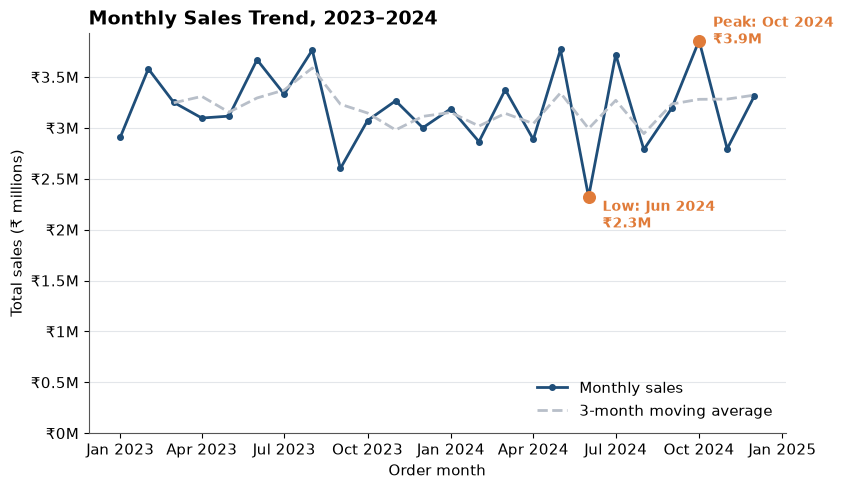

**Insight:** Sales were essentially flat in 2024 versus 2023 (₹38.7M → ₹38.1M), but individual months swing widely, from ₹2.3M in Jun 2024 to ₹3.9M in Oct 2024. The business is not growing year on year, so management should look at what drives the strong months and the weak ones rather than assume a rising trend.

In [8]:

monthly = df.groupby("Month")["Sales"].sum()
roll = monthly.rolling(3).mean()
yearly = df.groupby("Year")["Sales"].sum()
growth = yearly.get(2024, np.nan) / yearly.get(2023, np.nan) - 1
peak_m, low_m = monthly.idxmax(), monthly.idxmin()

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, color=BLUE, marker="o", markersize=4, linewidth=2, label="Monthly sales")
ax.plot(roll.index, roll.values, color=GRAY, linestyle="--", linewidth=2, label="3-month moving average")
ax.scatter([peak_m], [monthly[peak_m]], color=ORANGE, zorder=5, s=70)
ax.annotate(f"Peak: {peak_m:%b %Y}\n{m1(monthly[peak_m])}", (peak_m, monthly[peak_m]),
            textcoords="offset points", xytext=(10, -2), color=ORANGE, fontsize=10, weight="bold")
ax.scatter([low_m], [monthly[low_m]], color=ORANGE, zorder=5, s=70)
ax.annotate(f"Low: {low_m:%b %Y}\n{m1(monthly[low_m])}", (low_m, monthly[low_m]),
            textcoords="offset points", xytext=(10, -22), color=ORANGE, fontsize=10, weight="bold")
ax.set_title("Monthly Sales Trend, 2023–2024")
ax.set_xlabel("Order month")
ax.set_ylabel("Total sales (₹ millions)")
ax.yaxis.set_major_formatter(FuncFormatter(inr_m))
ax.set_ylim(0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
light_ygrid(ax)
ax.legend(frameon=False, loc="lower right")
trend_txt = ("were essentially flat" if abs(growth) < 0.03 else f"{'grew' if growth > 0 else 'fell'} {abs(growth):.1%}")
cap = (f"Sales {trend_txt} in 2024 versus 2023 ({m1(yearly.get(2023, 0))} → {m1(yearly.get(2024, 0))}), "
       f"but individual months swing widely, from {m1(monthly[low_m])} in {low_m:%b %Y} to {m1(monthly[peak_m])} in {peak_m:%b %Y}. "
       f"The business is not growing year on year, so management should look at what drives the strong months and the weak ones rather than assume a rising trend.")
finish(fig, "01_monthly_sales_trend", "Monthly Sales Trend", "1. Overview: the sales trend", cap)

### Section B: Where do sales come from? (Region and Product Category)

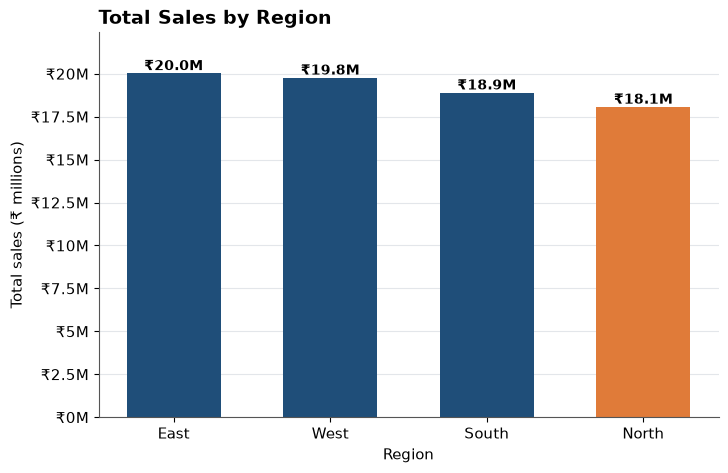

**Insight:** East leads with ₹20.0M (26% of sales), while North (highlighted) trails by 11% at ₹18.1M. Regional totals are fairly close, so the gap is a targeted growth opportunity in North rather than a structural problem.

In [9]:

reg = df.groupby("Region").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Sales", ascending=False)
worst_reg, best_reg = reg["Sales"].idxmin(), reg["Sales"].idxmax()
colors = [ORANGE if r == worst_reg else BLUE for r in reg.index]

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(reg.index, reg["Sales"], color=colors, width=0.6)
for b, v in zip(bars, reg["Sales"]):
    ax.text(b.get_x() + b.get_width() / 2, v, m1(v), ha="center", va="bottom", fontsize=10, weight="bold")
ax.set_title("Total Sales by Region")
ax.set_xlabel("Region")
ax.set_ylabel("Total sales (₹ millions)")
ax.yaxis.set_major_formatter(FuncFormatter(inr_m))
ax.set_ylim(0, reg["Sales"].max() * 1.12)
light_ygrid(ax)
gap = reg["Sales"].max() / reg["Sales"].min() - 1
margin_reg = (reg["Profit"] / reg["Sales"])
cap = (f"{best_reg} leads with {m1(reg.loc[best_reg, 'Sales'])} ({reg.loc[best_reg, 'Sales'] / reg['Sales'].sum():.0%} of sales), "
       f"while {worst_reg} (highlighted) trails by {gap:.0%} at {m1(reg.loc[worst_reg, 'Sales'])}. "
       f"Regional totals are fairly close, so the gap is a targeted growth opportunity in {worst_reg} rather than a structural problem.")
finish(fig, "02_sales_by_region", "Total Sales by Region", "2. Where sales come from: region and category", cap)

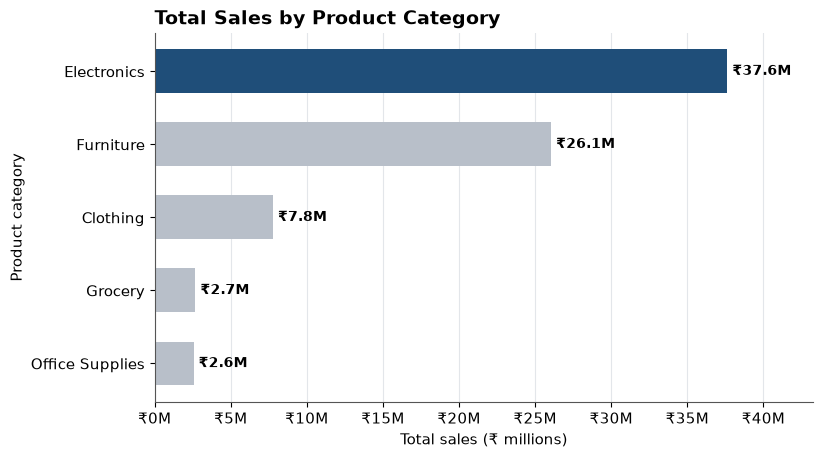

**Insight:** Electronics alone brings in 49% of all sales (₹37.6M), far ahead of Office Supplies at ₹2.6M. Revenue is concentrated in a few categories, so stock availability and pricing in Electronics matter most to the overall result.

In [10]:

cat = df.groupby("Product_Category").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum")).sort_values("Sales")
top_cat = cat["Sales"].idxmax()
colors = [BLUE if c == top_cat else GRAY for c in cat.index]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.barh(cat.index, cat["Sales"], color=colors, height=0.6)
for b, v in zip(bars, cat["Sales"]):
    ax.text(v, b.get_y() + b.get_height() / 2, f" {m1(v)}", va="center", fontsize=10, weight="bold")
ax.set_title("Total Sales by Product Category")
ax.set_xlabel("Total sales (₹ millions)")
ax.set_ylabel("Product category")
ax.xaxis.set_major_formatter(FuncFormatter(inr_m))
ax.set_xlim(0, cat["Sales"].max() * 1.15)
ax.xaxis.grid(True, color="#E3E6EA", linewidth=0.8)
ax.set_axisbelow(True)
low_cat = cat["Sales"].idxmin()
share_top = cat.loc[top_cat, "Sales"] / cat["Sales"].sum()
cap = (f"{top_cat} alone brings in {share_top:.0%} of all sales ({m1(cat.loc[top_cat, 'Sales'])}), "
       f"far ahead of {low_cat} at {m1(cat.loc[low_cat, 'Sales'])}. "
       f"Revenue is concentrated in a few categories, so stock availability and pricing in {top_cat} matter most to the overall result.")
finish(fig, "03_sales_by_category", "Total Sales by Product Category", "2. Where sales come from: region and category", cap)

### Section C: Who are the customers? (Age, Income, Segment)

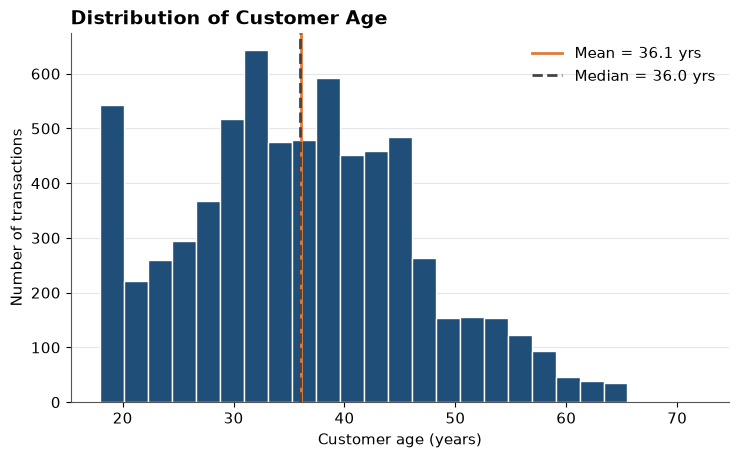

**Insight:** Customer age is roughly symmetric (skewness 0.27) with mean and median both near 36 years, and 67% of transactions come from customers aged 25–45. Marketing and product mix should therefore be built around working-age adults rather than very young or senior buyers.

In [11]:
age = df["Age"].dropna()
skew_age = age.skew()

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(age, bins=25, color=BLUE, edgecolor="white")
ax.axvline(age.mean(), color=ORANGE, linewidth=2, label=f"Mean = {age.mean():.1f} yrs")
ax.axvline(age.median(), color="#444444", linestyle="--", linewidth=2, label=f"Median = {age.median():.1f} yrs")
ax.set_title("Distribution of Customer Age")
ax.set_xlabel("Customer age (years)")
ax.set_ylabel("Number of transactions")
light_ygrid(ax)
ax.legend(frameon=False)
share_core = ((age >= 25) & (age <= 45)).mean()
skew_word = "roughly symmetric" if abs(skew_age) < 0.5 else ("right-skewed" if skew_age > 0 else "left-skewed")
cap = (f"Customer age is {skew_word} (skewness {skew_age:.2f}) with mean and median both near {age.median():.0f} years, "
       f"and {share_core:.0%} of transactions come from customers aged 25–45. "
       f"Marketing and product mix should therefore be built around working-age adults rather than very young or senior buyers.")
finish(fig, "04_age_distribution", "Distribution of Customer Age", "3. Who the customers are", cap)

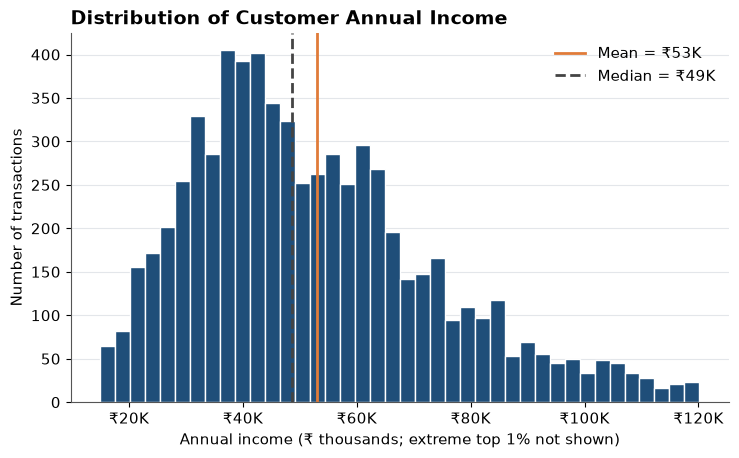

**Insight:** Income is clearly right-skewed (skewness 0.94): the mean (₹53K) sits above the median (₹49K) because a small group of high earners pulls the average up. For planning, the median is the fairer picture of a typical customer, and premium offers can target the long upper tail.

In [12]:

inc = df["Income"].dropna()
skew_inc = inc.skew()
p99 = inc.quantile(0.99)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.hist(inc[inc <= p99], bins=40, color=BLUE, edgecolor="white")
ax.axvline(inc.mean(), color=ORANGE, linewidth=2, label=f"Mean = ₹{inc.mean() / 1e3:.0f}K")
ax.axvline(inc.median(), color="#444444", linestyle="--", linewidth=2, label=f"Median = ₹{inc.median() / 1e3:.0f}K")
ax.set_title("Distribution of Customer Annual Income")
ax.set_xlabel("Annual income (₹ thousands; extreme top 1% not shown)")
ax.set_ylabel("Number of transactions")
ax.xaxis.set_major_formatter(FuncFormatter(inr_k))
light_ygrid(ax)
ax.legend(frameon=False)
cap = (f"Income is clearly right-skewed (skewness {skew_inc:.2f}): the mean (₹{inc.mean() / 1e3:.0f}K) sits above the median "
       f"(₹{inc.median() / 1e3:.0f}K) because a small group of high earners pulls the average up. "
       f"For planning, the median is the fairer picture of a typical customer, and premium offers can target the long upper tail.")
finish(fig, "05_income_distribution", "Distribution of Customer Annual Income", "3. Who the customers are", cap)

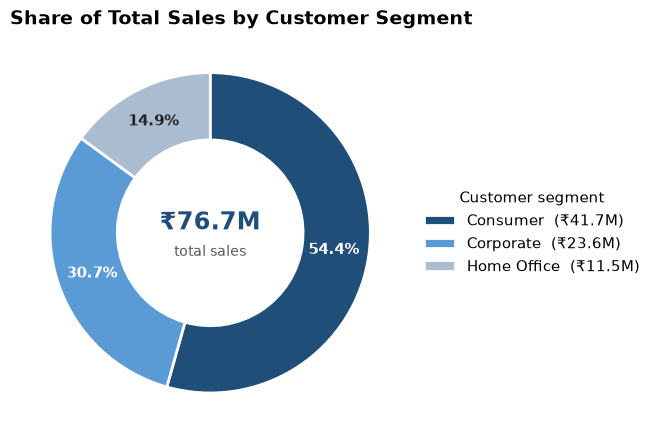

**Insight:** Consumer customers generate 54% of sales, with Corporate buyers adding 31% and Home Office 15%. Because Consumer accounts for most of the revenue, retention offers there protect the most sales, while Corporate and Home Office are the places to grow bulk and repeat orders.

In [13]:

seg = df.groupby("Customer_Segment")["Sales"].sum().sort_values(ascending=False)
seg_cols = [SEG_COLORS[s] for s in seg.index]

fig, ax = plt.subplots(figsize=(7.5, 5.2))
wedges, texts, autotexts = ax.pie(
    seg.values, colors=seg_cols, startangle=90, counterclock=False, autopct="%1.1f%%", pctdistance=0.78,
    wedgeprops={"width": 0.42, "edgecolor": "white", "linewidth": 2})
for t in autotexts:
    t.set_color("white" if t.get_text() and float(t.get_text().strip("%")) > 30 else "#222222")
    t.set_fontweight("bold")
ax.text(0, 0.06, m1(seg.sum()), ha="center", va="center", fontsize=17, weight="bold", color=BLUE)
ax.text(0, -0.12, "total sales", ha="center", va="center", fontsize=10, color="#555555")
ax.legend(wedges, [f"{s}  ({m1(v)})" for s, v in seg.items()], title="Customer segment",
          loc="center left", bbox_to_anchor=(1.0, 0.5), frameon=False)
ax.set_title("Share of Total Sales by Customer Segment")
top_seg = seg.index[0]
cap = (f"{top_seg} customers generate {seg.iloc[0] / seg.sum():.0%} of sales, with Corporate buyers adding {seg.get('Corporate', 0) / seg.sum():.0%} "
       f"and Home Office {seg.get('Home Office', 0) / seg.sum():.0%}. "
       f"Because {top_seg} accounts for most of the revenue, retention offers there protect the most sales, while Corporate and Home Office are the places to grow bulk and repeat orders.")
finish(fig, "06_segment_share_donut", "Share of Total Sales by Customer Segment", "3. Who the customers are", cap)

### Section D: Spread and relationships (Box plot and Scatter plots)

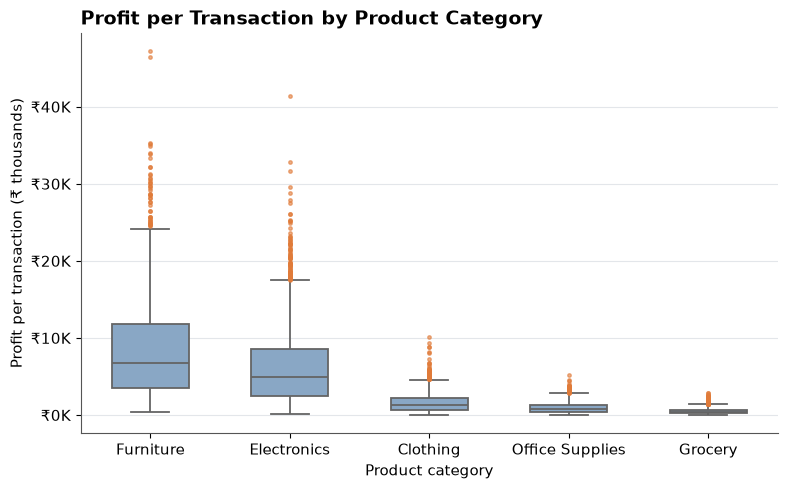

**Insight:** Furniture has the highest typical profit per order (median ₹6,717) and the widest spread (IQR ₹8,234), while Grocery orders are small and consistent (median ₹407). The orange dots are unusually large orders; they are valuable, but they make profit from high-ticket categories much harder to forecast.

In [14]:

order = df.groupby("Product_Category")["Profit"].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(9, 5.2))
sns.boxplot(data=df, x="Product_Category", y="Profit", order=order, color=LIGHT_BLUE, width=0.55,
            fliersize=2.5, flierprops={"markerfacecolor": ORANGE, "markeredgecolor": ORANGE, "alpha": 0.6},
            linewidth=1.3, ax=ax)
ax.set_title("Profit per Transaction by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Profit per transaction (₹ thousands)")
ax.yaxis.set_major_formatter(FuncFormatter(inr_k))
light_ygrid(ax)
med = df.groupby("Product_Category")["Profit"].median()
iqr = df.groupby("Product_Category")["Profit"].apply(lambda s: s.quantile(.75) - s.quantile(.25))
widest = iqr.idxmax()
cap = (f"{order[0]} has the highest typical profit per order (median ₹{med[order[0]]:,.0f}) and the widest spread "
       f"(IQR ₹{iqr[widest]:,.0f}), while {order[-1]} orders are small and consistent (median ₹{med[order[-1]]:,.0f}). "
       f"The orange dots are unusually large orders; they are valuable, but they make profit from high-ticket categories much harder to forecast.")
finish(fig, "07_profit_boxplot_by_category", "Profit per Transaction by Product Category", "4. Spread and relationships", cap)

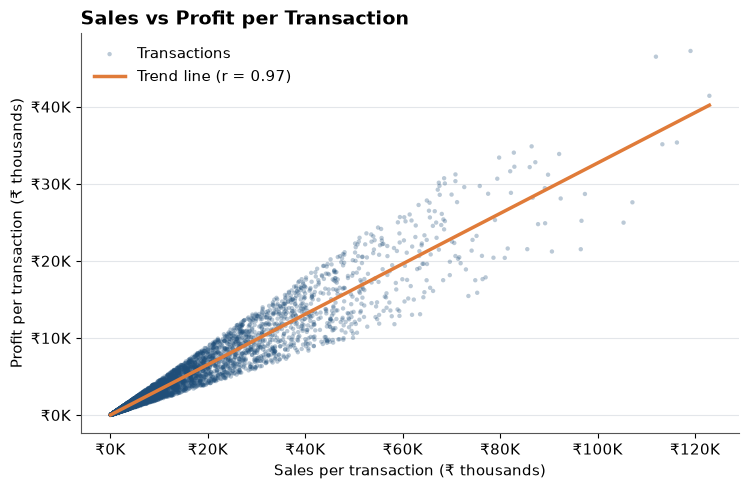

**Insight:** Sales and profit move together very closely (correlation 0.97); on average every extra ₹100 of sales adds about ₹33 of profit. Profit margin stays steady at about 33%, so growing order value is a reliable way to grow profit.

In [15]:

d8 = df[["Sales", "Profit"]].dropna()
r8 = d8["Sales"].corr(d8["Profit"])
slope, intercept = np.polyfit(d8["Sales"], d8["Profit"], 1)
xs = np.linspace(d8["Sales"].min(), d8["Sales"].max(), 100)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(d8["Sales"], d8["Profit"], s=10, alpha=0.3, color=BLUE, edgecolor="none", label="Transactions")
ax.plot(xs, slope * xs + intercept, color=ORANGE, linewidth=2.5, label=f"Trend line (r = {r8:.2f})")
ax.set_title("Sales vs Profit per Transaction")
ax.set_xlabel("Sales per transaction (₹ thousands)")
ax.set_ylabel("Profit per transaction (₹ thousands)")
ax.xaxis.set_major_formatter(FuncFormatter(inr_k))
ax.yaxis.set_major_formatter(FuncFormatter(inr_k))
light_ygrid(ax)
ax.legend(frameon=False, loc="upper left")
cap = (f"Sales and profit move together very closely (correlation {r8:.2f}); on average every extra ₹100 of sales adds about ₹{slope * 100:.0f} of profit. "
       f"Profit margin stays steady at about {KPI['profit_margin']:.0%}, so growing order value is a reliable way to grow profit.")
finish(fig, "08_sales_vs_profit_scatter", "Sales vs Profit", "4. Spread and relationships", cap)

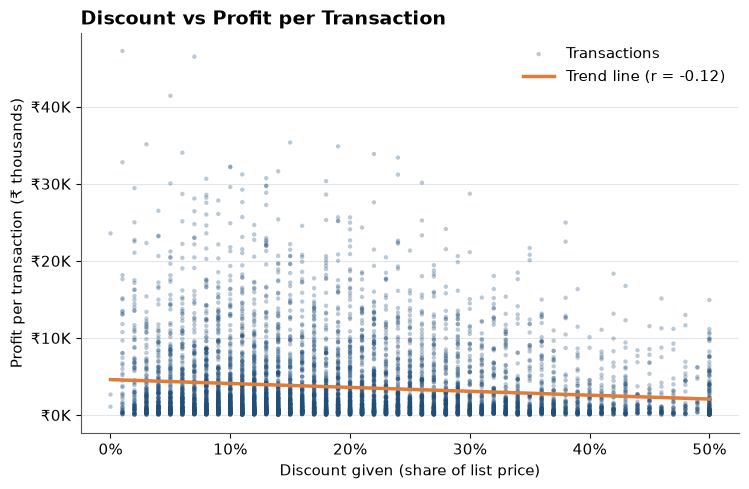

**Insight:** The relationship between discount and profit is weak and negative (correlation -0.12); each extra 10 percentage points of discount lowers profit by about ₹505 per order on average. Discount level on its own does not explain profit, so discounts should be judged per category and order size rather than cut across the board.

In [16]:

d9 = df[["Discount", "Profit"]].dropna()
r9 = d9["Discount"].corr(d9["Profit"])
slope9, int9 = np.polyfit(d9["Discount"], d9["Profit"], 1)
xs9 = np.linspace(0, 0.5, 100)

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(d9["Discount"], d9["Profit"], s=10, alpha=0.3, color=BLUE, edgecolor="none", label="Transactions")
ax.plot(xs9, slope9 * xs9 + int9, color=ORANGE, linewidth=2.5, label=f"Trend line (r = {r9:.2f})")
ax.set_title("Discount vs Profit per Transaction")
ax.set_xlabel("Discount given (share of list price)")
ax.set_ylabel("Profit per transaction (₹ thousands)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{x:.0%}"))
ax.yaxis.set_major_formatter(FuncFormatter(inr_k))
light_ygrid(ax)
ax.legend(frameon=False, loc="upper right")
direction = "negative" if r9 < 0 else "positive"
cap = (f"The relationship between discount and profit is {strength(r9)} and {direction} (correlation {r9:.2f}); "
       f"each extra 10 percentage points of discount {'lowers' if slope9 < 0 else 'raises'} profit by about ₹{abs(slope9) * 0.1:,.0f} per order on average. "
       f"Discount level on its own does not explain profit, so discounts should be judged per category and order size rather than cut across the board.")
finish(fig, "09_discount_vs_profit_scatter", "Discount vs Profit", "4. Spread and relationships", cap)

### Section E: Combined heatmap view

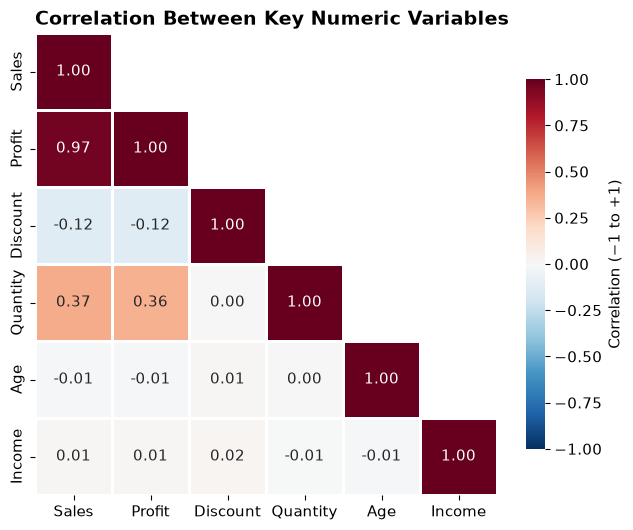

**Insight:** The strongest link is between Profit and Sales (r = 0.97), meaning profit is driven mainly by how much is sold per order. Customer age and income show almost no correlation with sales or profit (correlations of at most 0.01), so order size matters far more than who the customer is.

In [17]:

cols = ["Sales", "Profit", "Discount", "Quantity", "Age", "Income"]
corr = df[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", square=True, cbar_kws={"label": "Correlation (−1 to +1)", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation Between Key Numeric Variables")
pairs = corr.where(~mask & (np.eye(len(cols)) == 0)).stack().sort_values(key=abs, ascending=False)
(a1, b1), v1 = pairs.index[0], pairs.iloc[0]
weak_cust = max(abs(corr.loc["Age", ["Sales", "Profit"]]).max(), abs(corr.loc["Income", ["Sales", "Profit"]]).max())
cap = (f"The strongest link is between {a1} and {b1} (r = {v1:.2f}), meaning profit is driven mainly by how much is sold per order. "
       f"Customer age and income show almost no correlation with sales or profit (correlations of at most {weak_cust:.2f}), "
       f"so order size matters far more than who the customer is.")
finish(fig, "10_correlation_heatmap", "Correlation Heatmap", "5. Combined heatmap view", cap)

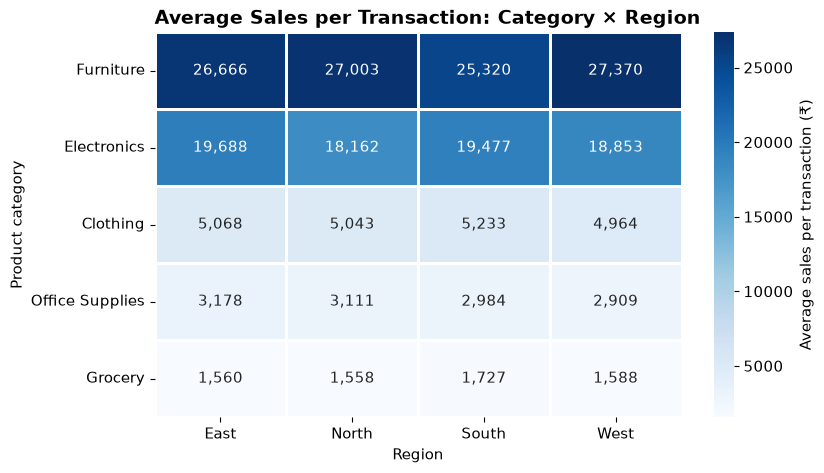

**Insight:** Average order value is highest for Furniture in the West region (₹27,370) and lowest for Grocery in North (₹1,558). Category matters far more than region: within each category the average order is similar in all four regions, so regional growth will come from winning more orders, not from larger baskets.

In [18]:

piv = df.pivot_table(index="Product_Category", columns="Region", values="Sales", aggfunc="mean")
piv = piv.loc[piv.mean(axis=1).sort_values(ascending=False).index]
stack = piv.stack()
(best_c, best_r), best_v = stack.idxmax(), stack.max()
(low_c, low_r), low_v = stack.idxmin(), stack.min()

fig, ax = plt.subplots(figsize=(8.5, 5))
sns.heatmap(piv, annot=True, fmt=",.0f", cmap="Blues", linewidths=1, linecolor="white",
            cbar_kws={"label": "Average sales per transaction (₹)"}, ax=ax)
ax.set_title("Average Sales per Transaction: Category × Region")
ax.set_xlabel("Region")
ax.set_ylabel("Product category")
ax.tick_params(axis="y", rotation=0)
cap = (f"Average order value is highest for {best_c} in the {best_r} region (₹{best_v:,.0f}) and lowest for {low_c} in {low_r} (₹{low_v:,.0f}). "
       f"Category matters far more than region: within each category the average order is similar in all four regions, "
       f"so regional growth will come from winning more orders, not from larger baskets.")
finish(fig, "11_category_region_heatmap", "Average Sales: Category x Region", "5. Combined heatmap view", cap)

### Section F: Returns and satisfaction

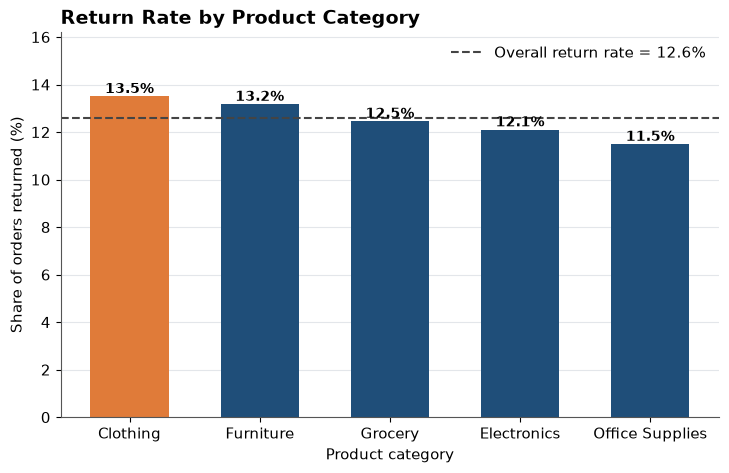

**Insight:** Overall 12.6% of orders are returned, and Clothing is the worst category at 13.5% versus 11.5% for Office Supplies, a modest gap that shows returns are a business-wide issue. Returned orders represent ₹9.0M of sales (12%), so fixing quality or description issues in Clothing would protect real revenue.

In [19]:

ret = (df.groupby("Product_Category")["Returned_Flag"].mean() * 100).sort_values(ascending=False)
overall = df["Returned_Flag"].mean() * 100
colors = [ORANGE if c == ret.index[0] else BLUE for c in ret.index]

fig, ax = plt.subplots(figsize=(8.5, 5))
bars = ax.bar(ret.index, ret.values, color=colors, width=0.6)
for b, v in zip(bars, ret.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=10, weight="bold")
ax.axhline(overall, color="#444444", linestyle="--", linewidth=1.5, label=f"Overall return rate = {overall:.1f}%")
ax.set_title("Return Rate by Product Category")
ax.set_xlabel("Product category")
ax.set_ylabel("Share of orders returned (%)")
ax.set_ylim(0, ret.max() * 1.2)
light_ygrid(ax)
ax.legend(frameon=False)
lost = df.loc[df["Returned"] == "Yes", "Sales"].sum()
cap = (f"Overall {overall:.1f}% of orders are returned, and {ret.index[0]} is the worst category at {ret.iloc[0]:.1f}% "
       f"versus {ret.iloc[-1]:.1f}% for {ret.index[-1]}, a modest gap that shows returns are a business-wide issue. "
       f"Returned orders represent {m1(lost)} of sales ({lost / df['Sales'].sum():.0%}), so fixing quality or description issues in {ret.index[0]} would protect real revenue.")
finish(fig, "12_return_rate_by_category", "Return Rate by Product Category", "6. Returns and satisfaction", cap)

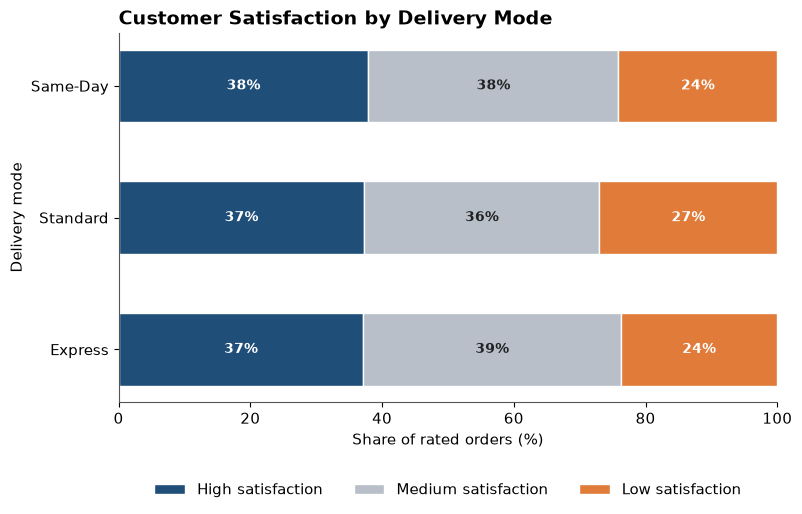

**Insight:** 'High' satisfaction is almost identical across delivery modes (37%–38%), and only about 24–27% of orders get a 'Low' rating (Standard is highest). Faster delivery does not buy higher satisfaction, so product quality and returns deserve more attention than shipping speed.

In [20]:

sat = df.dropna(subset=["Satisfaction_Level"])
ct = pd.crosstab(sat["Delivery_Mode"], sat["Satisfaction_Level"], normalize="index") * 100
ct = ct[["Low", "Medium", "High"]]
ct = ct.sort_values("High", ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
left = np.zeros(len(ct))
for level in ["High", "Medium", "Low"]:
    ax.barh(ct.index, ct[level], left=left, color=SAT_COLORS[level], label=f"{level} satisfaction", height=0.55, edgecolor="white")
    for i, v in enumerate(ct[level]):
        ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white" if level != "Medium" else "#222222", fontsize=10, weight="bold")
    left += ct[level].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("Customer Satisfaction by Delivery Mode")
ax.set_xlabel("Share of rated orders (%)")
ax.set_ylabel("Delivery mode")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
best_d, worst_d = ct["High"].idxmax(), ct["High"].idxmin()
worst_low = ct["Low"].idxmax()
if ct["High"].max() - ct["High"].min() < 5:
    cap = (f"'High' satisfaction is almost identical across delivery modes ({ct['High'].min():.0f}%–{ct['High'].max():.0f}%), and only about "
           f"{ct['Low'].min():.0f}–{ct['Low'].max():.0f}% of orders get a 'Low' rating ({worst_low} is highest). "
           f"Faster delivery does not buy higher satisfaction, so product quality and returns deserve more attention than shipping speed.")
else:
    cap = (f"{best_d} delivery earns the most 'High' satisfaction ({ct.loc[best_d, 'High']:.0f}%) while {worst_d} has the least "
           f"({ct.loc[worst_d, 'High']:.0f}%). Delivery speed visibly changes satisfaction, so improving the weakest mode is a quick win.")
finish(fig, "13_satisfaction_by_delivery", "Satisfaction by Delivery Mode", "6. Returns and satisfaction", cap)

In [21]:

(OUT / "charts_meta.json").write_text(json.dumps({"kpi": KPI, "cleaning": log, "charts": CHARTS}, indent=2))
print(f"Done: {len(CHARTS)} charts saved in {CHART_DIR}")

Done: 13 charts saved in d:\College_CODE\HCL\Data-project\outputs\charts
